# MAE Competencia Regresión 202620

El gerente de la empresa inmobiliaria CasaRoble está interesado en predecir el precio de venta de una vivienda a partir de un conjunto de variables que tiene a su disposición, tales como año de construcción, tamaño, número de parqueaderos, entre otras. Para el efecto cuenta con alguna información que ha sido recolectada durante los últimos diez años sobre el precio de venta de apartamentos y algunas variables explicativas.

Dataset Description
Variables de entrada:

‘# - índice que indica la posición de la observación.

1- SalePrice: precio de venta en dólares.

2- YearBuilt: año de construcción

3- YrSold: año de venta

4- MonthSold: mes de venta

5- Size.sqf: tamaño del apartamento en pies cuadrados

6- Floor: piso en el que se ubica la propiedad

7- HallwayType: tipo de vestíbulo

8- HeatingType: tipo de calefacción.

9- AptManageType: forma en la que se administraba la propiedad

10- N_Parkinglot.Ground: número de estacionamientos en el suelo.

11- N_Parkinglot.Basement: número de estacionamientos en el sótano.

12- TimeToBusStop: tiempo hasta una parada de autobús

13- TimeToSubway: tiempo hasta una estación del subterráneo

14- N_APT: número de apartamentos en el complejo.

15- N_manager: número de personas que atienden las instalaciones del apartamento.

16- N_elevators: número de ascensores.

17- SubwayStation: nombre de la estación más cercana.

18- N_FacilitiesNearBy.PublicOffice: número de oficinas públicas cercanas.

19- N_FacilitiesNearBy.Hospital: número de hospitales cercanos.

20- N_FacilitiesNearBy.Dpartmentstore: número de tiendas departamentales cercanas

21- N_FacilitiesNearBy.Mall: número de centros comerciales cercanos.

22- N_FacilitiesNearBy.ETC. número de otras facilidades cercanas (p.ej. hoteles)

23- N_FacilitiesNearBy.Park. número de parques cercanos.

24- N_SchoolNearBy.Elementary: número de escuelas primarias cercanas.

25- N_SchoolNearBy.Middle: número de escuelas medias cercanas.

26- N_SchoolNearBy.High. número de escuelas secundarias cercanas.

27- N_SchoolNearBy.University. número de universidades cercanas.

28- N_FacilitiesInApt: número de instalaciones del apartamento (p.ej. piscina, gimnasio)

29- N_FacilitiesNearBy.Total: número total de instalaciones cercanas.

30- N_SchoolNearBy.Total: número total de escuelas cercanas.

## 3.1 Contexto y datos

In [64]:
import os
from pathlib import Path
from dotenv import load_dotenv

env_path = Path.cwd() / ".env"
if not env_path.is_file():
    raise FileNotFoundError("No se encontro .env")

load_dotenv(env_path, override=True)
if not os.environ.get("KAGGLE_API_TOKEN", "").strip():
    raise ValueError("Falta KAGGLE_API_TOKEN en el archivo .env.")
print("Token cargado desde .env")

Token cargado desde .env


In [65]:
import kagglehub

path = kagglehub.competition_download("mae-competencia-regresion-202620")
data_dir = Path(path)
print("Carpeta de datos:", data_dir)
print("Archivos disponibles:")
for archivo in sorted(data_dir.rglob("*")):
    if archivo.is_file():
        print(" -", archivo.relative_to(data_dir))

Carpeta de datos: C:\Users\Silvi\.cache\kagglehub\competitions\mae-competencia-regresion-202620
Archivos disponibles:
 - Test real state.csv
 - Train real state.csv


In [66]:
import pandas as pd

# Usa la carpeta obtenida en la celda de descarga.
df_train = pd.read_csv(data_dir / "Train real state.csv")
df_test = pd.read_csv(data_dir / "Test real state.csv")

print("Entrenamiento (filas, columnas):", df_train.shape)
display(df_train.head())
print("Prueba (filas, columnas):", df_test.shape)
print("Columnas de train que no estan en test:", set(df_train.columns) - set(df_test.columns))

Entrenamiento (filas, columnas): (4124, 31)


,id,SalePrice,YearBuilt,YrSold,MonthSold,Size.sqf.,Floor,HallwayType,HeatingType,AptManageType,...,N_FacilitiesNearBy.Mall.,N_FacilitiesNearBy.ETC.,N_FacilitiesNearBy.Park.,N_SchoolNearBy.Elementary.,N_SchoolNearBy.Middle.,N_SchoolNearBy.High.,N_SchoolNearBy.University.,N_FacilitiesInApt,N_FacilitiesNearBy.Total.,N_SchoolNearBy.Total.
0,1,141592,2006,2007,8,814,3,terraced,individual_heating,management_in_trust,...,1,1,0,3,2,2,2,5,6,9
1,2,51327,1985,2007,8,587,8,corridor,individual_heating,self_management,...,1,2,1,2,1,1,0,3,12,4
2,3,48672,1985,2007,8,587,6,corridor,individual_heating,self_management,...,1,2,1,2,1,1,0,3,12,4
3,5,221238,1993,2007,8,1761,3,mixed,individual_heating,management_in_trust,...,1,5,0,4,3,5,5,4,14,17
4,7,78318,1992,2007,8,644,2,mixed,individual_heating,self_management,...,1,1,0,3,3,4,4,3,9,14


Prueba (filas, columnas): (1767, 30)
Columnas de train que no estan en test: {'SalePrice'}


In [67]:
# trabajamos con los datos de train
df_train.info() # miramos el tipo de datos de cada variable y la cantidad de valores nulos

<class 'pandas.DataFrame'>
RangeIndex: 4124 entries, 0 to 4123
Data columns (total 31 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   id                                  4124 non-null   int64
 1   SalePrice                           4124 non-null   int64
 2   YearBuilt                           4124 non-null   int64
 3   YrSold                              4124 non-null   int64
 4   MonthSold                           4124 non-null   int64
 5   Size.sqf.                           4124 non-null   int64
 6   Floor                               4124 non-null   int64
 7   HallwayType                         4124 non-null   str  
 8   HeatingType                         4124 non-null   str  
 9   AptManageType                       4124 non-null   str  
 10  N_Parkinglot.Ground.                4124 non-null   int64
 11  N_Parkinglot.Basement.              4124 non-null   int64
 12  TimeToBusStop    

In [68]:
df_train.describe().T # miramos un resumen estadístico de las variables numéricas

,count,mean,std,min,25%,50%,75%,max
id,4124.0,2951.804801,1698.599944,1.0,1476.75,2966.5,4419.5,5890.0
SalePrice,4124.0,221687.617847,106353.186576,32743.0,145464.25,207964.0,291150.0,585840.0
YearBuilt,4124.0,2002.974782,8.846158,1978.0,1993.00,2006.0,2008.0,2015.0
YrSold,4124.0,2012.701988,2.903440,2007.0,2010.00,2013.0,2015.0,2017.0
MonthSold,4124.0,6.162706,3.382476,1.0,3.00,6.0,9.0,12.0
Size.sqf.,4124.0,955.909069,376.905448,135.0,644.00,910.0,1149.0,2337.0
Floor,4124.0,12.064743,7.616469,1.0,6.00,11.0,17.0,43.0
N_Parkinglot.Ground.,4124.0,194.698836,218.142679,0.0,11.00,100.0,249.0,713.0
N_Parkinglot.Basement.,4124.0,571.570805,407.517420,0.0,184.00,536.0,798.0,1321.0
N_APT,4124.0,5.630213,2.785791,1.0,3.00,7.0,8.0,13.0


In [69]:
# listado de variables categoricas con la frecuencia de cada valor
categoricas = df_train.select_dtypes(exclude="number").columns
{col: df_train[col].value_counts().to_dict() for col in categoricas}

{'HallwayType': {'terraced': 2505, 'mixed': 1183, 'corridor': 436},
 'HeatingType': {'individual_heating': 3912, 'central_heating': 212},
 'AptManageType': {'management_in_trust': 3876, 'self_management': 248},
 'TimeToBusStop': {'0~5min': 3164, '5min~10min': 924, '10min~15min': 36},
 'TimeToSubway': {'0-5min': 1946,
  '5min~10min': 791,
  '15min~20min': 658,
  '10min~15min': 567,
  'no_bus_stop_nearby': 162},
 'SubwayStation': {'Kyungbuk_uni_hospital': 1176,
  'Myung-duk': 1045,
  'Bangoge': 525,
  'Banwoldang': 514,
  'Sin-nam': 459,
  'no_subway_nearby': 270,
  'Chil-sung-market': 75,
  'Daegu': 60}}

## 3.2 Limpieza y validación

In [70]:
# Valores faltantes y duplicados
print("Valores nulos en total:", int(df_train.isna().sum().sum()))
print("ids repetidos:", int(df_train["id"].duplicated().sum()))

columnas_sin_id = df_train.columns.drop("id")
filas_repetidas = df_train.duplicated(subset=columnas_sin_id, keep=False)
print("Filas identicas a otra (sin contar el id):", int(filas_repetidas.sum()),
      "en", df_train[filas_repetidas].groupby(list(columnas_sin_id)).ngroups, "grupos")
print("Filas que sobran si se dejara una por grupo:",
      int(df_train.duplicated(subset=columnas_sin_id).sum()))

# Sensibilidad: precio con y sin las filas repetidas
sin_repetidas = df_train.drop_duplicates(subset=columnas_sin_id)
print("Precio medio con / sin repetidas:", round(df_train["SalePrice"].mean()), "/", round(sin_repetidas["SalePrice"].mean()))
print("Precio mediano con / sin repetidas:", df_train["SalePrice"].median(), "/", sin_repetidas["SalePrice"].median())

Valores nulos en total: 0
ids repetidos: 0
Filas identicas a otra (sin contar el id): 300 en 108 grupos
Filas que sobran si se dejara una por grupo: 192
Precio medio con / sin repetidas: 221688 / 225857
Precio mediano con / sin repetidas: 207964.0 / 212389.0


In [71]:
# Coherencia entre variables
print("Ventas anteriores al año de construccion:", int((df_train["YrSold"] < df_train["YearBuilt"]).sum()))

instalaciones = ["N_FacilitiesNearBy.PublicOffice.", "N_FacilitiesNearBy.Hospital.",
                 "N_FacilitiesNearBy.Dpartmentstore.", "N_FacilitiesNearBy.Mall.",
                 "N_FacilitiesNearBy.ETC.", "N_FacilitiesNearBy.Park."]
escuelas = ["N_SchoolNearBy.Elementary.", "N_SchoolNearBy.Middle.",
            "N_SchoolNearBy.High.", "N_SchoolNearBy.University."]
print("Total de instalaciones distinto a la suma:",
      int((df_train[instalaciones].sum(axis=1) != df_train["N_FacilitiesNearBy.Total."]).sum()))
print("Total de escuelas distinto a la suma:",
      int((df_train[escuelas].sum(axis=1) != df_train["N_SchoolNearBy.Total."]).sum()))

Ventas anteriores al año de construccion: 0
Total de instalaciones distinto a la suma: 0
Total de escuelas distinto a la suma: 0


In [72]:
# TimeToSubway frente a la estacion mas cercana
pd.crosstab(df_train["TimeToSubway"], df_train["SubwayStation"])

SubwayStation,Bangoge,Banwoldang,Chil-sung-market,Daegu,Kyungbuk_uni_hospital,Myung-duk,Sin-nam,no_subway_nearby
TimeToSubway,,,,,,,,
0-5min,0,470,0,0,815,256,405,0
10min~15min,0,0,0,0,361,206,0,0
15min~20min,0,0,75,0,0,583,0,0
5min~10min,525,44,0,60,0,0,54,108
no_bus_stop_nearby,0,0,0,0,0,0,0,162


In [73]:
# Variables del complejo: se identifican los complejos por año de construccion, estacion y parqueaderos
llave_complejo = ["YearBuilt", "SubwayStation", "N_Parkinglot.Ground.", "N_Parkinglot.Basement."]
complejos = df_train.groupby(llave_complejo)
print("Complejos distintos:", complejos.ngroups)

variables_complejo = ["N_APT", "N_manager", "N_elevators", "HallwayType", "HeatingType",
                      "AptManageType", "TimeToSubway", "TimeToBusStop", "N_FacilitiesInApt",
                      "N_FacilitiesNearBy.Total.", "N_SchoolNearBy.Total."]
print("Complejos con mas de un valor en la variable:",
      {col: int((complejos[col].nunique() > 1).sum()) for col in variables_complejo})

# Complejos registrados sin ascensores y piso maximo vendido en ellos
sin_ascensor = df_train[df_train["N_elevators"] == 0]
print("Ventas en complejos con N_elevators = 0:", len(sin_ascensor))
sin_ascensor.groupby(llave_complejo[:2]).agg(ventas=("Floor", "size"), piso_maximo=("Floor", "max")).reset_index()

Complejos distintos: 26
Complejos con mas de un valor en la variable: {'N_APT': 0, 'N_manager': 0, 'N_elevators': 0, 'HallwayType': 0, 'HeatingType': 0, 'AptManageType': 0, 'TimeToSubway': 0, 'TimeToBusStop': 0, 'N_FacilitiesInApt': 0, 'N_FacilitiesNearBy.Total.': 0, 'N_SchoolNearBy.Total.': 0}
Ventas en complejos con N_elevators = 0: 754


,YearBuilt,SubwayStation,ventas,piso_maximo
0,2005,Bangoge,525,24
1,2006,Kyungbuk_uni_hospital,149,20
2,2014,Banwoldang,44,16
3,2014,no_subway_nearby,36,19


In [ ]:
orden_metro = ["0~5min", "5min~10min", "10min~15min", "15min~20min", "no_subway_nearby"]


def limpiar(df):
    df = df.copy()
    # Unificar el formato de TimeToSubway; las filas "no_bus_stop_nearby" se corrigen a "no_subway_nearby".
    df["TimeToSubway"] = df["TimeToSubway"].replace({
        "0-5min": "0~5min",
        "no_bus_stop_nearby": "no_subway_nearby",
    })
    df["TimeToSubway"] = pd.Categorical(df["TimeToSubway"], categories=orden_metro, ordered=True)
    # Variable derivada: antigüedad de la vivienda al momento de la venta
    df["Antiguedad"] = df["YrSold"] - df["YearBuilt"]
    return df

# Variables explicativas seleccionadas (en test no esta SalePrice)
variables_explicativas = [
    "Size.sqf.", "Antiguedad", "YrSold", "Floor",
    "HallwayType", "HeatingType", "AptManageType", "N_Parkinglot.Basement.",
    "TimeToSubway", "SubwayStation", "N_FacilitiesInApt",
    "N_FacilitiesNearBy.Total.", "N_SchoolNearBy.Total.",
]
df_train = limpiar(df_train)
df_reg = df_train.loc[:, ["SalePrice"] + variables_explicativas].copy()

print("Datos para el analisis (filas, columnas):", df_reg.shape)
print("Antiguedad: minimo", df_reg["Antiguedad"].min(), "- maximo", df_reg["Antiguedad"].max(),
      "- ventas en el mismo año de construccion:", int((df_reg["Antiguedad"] == 0).sum()))

Datos para el analisis (filas, columnas): (4124, 14)
Antiguedad: minimo 0 - maximo 39 - ventas en el mismo año de construccion: 235


In [75]:
# Validacion del archivo de prueba con los mismos criterios y la misma limpieza
print("Valores nulos en test:", int(df_test.isna().sum().sum()))
print("ids de test repetidos o presentes en train:", int(df_test["id"].duplicated().sum()),
      int(df_test["id"].isin(df_train["id"]).sum()))
print("Ventas anteriores al año de construccion:", int((df_test["YrSold"] < df_test["YearBuilt"]).sum()))
print("Etiquetas de TimeToSubway en test:", df_test["TimeToSubway"].value_counts().to_dict())
print("Filas 'no_bus_stop_nearby' sin estacion cercana:",
      int(((df_test["TimeToSubway"] == "no_bus_stop_nearby")
           & (df_test["SubwayStation"] == "no_subway_nearby")).sum()),
      "de", int((df_test["TimeToSubway"] == "no_bus_stop_nearby").sum()))

# Categorias de test que no aparecen en train
for col in df_test.select_dtypes(exclude="number").columns:
    nuevas = set(df_test[col]) - set(pd.read_csv(data_dir / "Train real state.csv")[col])
    print(f"{col}: categorias nuevas en test -> {nuevas or 'ninguna'}")

# Complejos de test que no estan en train
complejos_train = set(map(tuple, df_train[llave_complejo].drop_duplicates().to_numpy()))
complejos_test = set(map(tuple, df_test[llave_complejo].drop_duplicates().to_numpy()))
print("Complejos en test:", len(complejos_test), "- no vistos en train:", len(complejos_test - complejos_train))
print("Ventas en complejos con N_elevators = 0 en test:", int((df_test["N_elevators"] == 0).sum()))

df_test = limpiar(df_test)
df_test_reg = df_test.loc[:, ["id"] + variables_explicativas].copy()

# Rangos de test frente a train
numericas = df_reg.select_dtypes(include="number").columns.drop("SalePrice")
pd.DataFrame({
    "Min train": df_reg[numericas].min(), "Max train": df_reg[numericas].max(),
    "Min test": df_test_reg[numericas].min(), "Max test": df_test_reg[numericas].max(),
}).round(1)

Valores nulos en test: 0
ids de test repetidos o presentes en train: 0 0
Ventas anteriores al año de construccion: 0
Etiquetas de TimeToSubway en test: {'0-5min': 834, '5min~10min': 344, '15min~20min': 270, '10min~15min': 242, 'no_bus_stop_nearby': 77}
Filas 'no_bus_stop_nearby' sin estacion cercana: 77 de 77
HallwayType: categorias nuevas en test -> ninguna
HeatingType: categorias nuevas en test -> ninguna
AptManageType: categorias nuevas en test -> ninguna
TimeToBusStop: categorias nuevas en test -> ninguna
TimeToSubway: categorias nuevas en test -> ninguna
SubwayStation: categorias nuevas en test -> ninguna
Complejos en test: 26 - no vistos en train: 0
Ventas en complejos con N_elevators = 0 en test: 331


,Min train,Max train,Min test,Max test
Size.sqf.,135,2337,135,2337
Antiguedad,0,39,0,39
YrSold,2007,2017,2007,2017
Floor,1,43,1,43
N_Parkinglot.Basement.,0,1321,0,1321
N_FacilitiesInApt,1,10,1,10
N_FacilitiesNearBy.Total.,0,16,0,16
N_SchoolNearBy.Total.,0,17,0,17


## 3.3 Medidas de tendencia central y de dispersión

In [76]:
import numpy as np

datos_numericos = df_reg.select_dtypes(include="number").drop(columns=["YrSold"])


def media_recortada(serie, proporcion=0.10):
    # descarta el 10 % de los valores mas bajos y el 10 % de los mas altos
    valores = np.sort(serie.to_numpy())
    k = int(proporcion * len(valores))
    return valores[k:len(valores) - k].mean()


def atipicos_tukey(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    ric = q3 - q1
    return int(((serie < q1 - 1.5 * ric) | (serie > q3 + 1.5 * ric)).sum())


media = datos_numericos.mean()
desviacion = datos_numericos.std(ddof=1)

medidas_descriptivas = pd.DataFrame({
    "N validos": datos_numericos.count(),
    "Media": media,
    "Media recortada 10%": datos_numericos.apply(media_recortada),
    "Mediana": datos_numericos.median(),
    "Moda": pd.Series({col: datos_numericos[col].mode().tolist() for col in datos_numericos}),
    "Desviacion estandar": desviacion,
    "CV (%)": desviacion / media.replace(0, float("nan")) * 100,
    "Minimo": datos_numericos.min(),
    "Primer cuartil (Q1)": datos_numericos.quantile(0.25),
    "Tercer cuartil (Q3)": datos_numericos.quantile(0.75),
    "Maximo": datos_numericos.max(),
    "Rango": datos_numericos.max() - datos_numericos.min(),
    "Rango intercuartil": datos_numericos.quantile(0.75) - datos_numericos.quantile(0.25),
    "Asimetria": datos_numericos.skew(),
    "Atipicos (Tukey)": datos_numericos.apply(atipicos_tukey),
})
medidas_descriptivas.index.name = "Variable"

medidas_descriptivas.round(2).T

Variable,SalePrice,Size.sqf.,Antiguedad,Floor,N_Parkinglot.Basement.,N_FacilitiesInApt,N_FacilitiesNearBy.Total.,N_SchoolNearBy.Total.
N validos,4124,4124,4124,4124,4124,4124,4124,4124
Media,221687.62,955.91,9.73,12.06,571.57,5.83,9.85,10.87
Media recortada 10%,215916.43,922.89,8.67,11.44,554.62,5.7,9.96,10.98
Mediana,207964.0,910.0,7.0,11.0,536.0,5.0,9.0,10.0
Moda,[149274],[914],[3],[7],[536],[4],[9],[17]
Desviacion estandar,106353.19,376.91,8.59,7.62,407.52,2.32,3.45,4.43
CV (%),47.97,39.43,88.29,63.13,71.3,39.81,35.08,40.69
Minimo,32743,135,0,1,0,1,0,0
Primer cuartil (Q1),145464.25,644.0,3.0,6.0,184.0,4.0,8.0,7.0
Tercer cuartil (Q3),291150.0,1149.0,16.0,17.0,798.0,7.0,13.0,15.0


In [ ]:
# Limites de Tukey (Q1 - 1,5*RIC y Q3 + 1,5*RIC) y cantidad de atipicos por debajo y por encima.
q1 = datos_numericos.quantile(0.25)
q3 = datos_numericos.quantile(0.75)
limite_inferior = q1 - 1.5 * (q3 - q1)
limite_superior = q3 + 1.5 * (q3 - q1)
pd.DataFrame({
    "Minimo observado": datos_numericos.min(),
    "Limite inferior": limite_inferior,
    "Limite superior": limite_superior,
    "Atipicos bajos": (datos_numericos < limite_inferior).sum(),
    "Maximo observado": datos_numericos.max(),
    "Atipicos altos": (datos_numericos > limite_superior).sum(),
})

,Minimo observado,Limite inferior,Limite superior,Atipicos bajos,Maximo observado,Atipicos altos
SalePrice,32743,-73064.375,509678.625,0,585840,25
Size.sqf.,135,-113.500,1906.500,0,2337,88
Antiguedad,0,-16.500,35.500,0,39,29
Floor,1,-10.500,33.500,0,43,42
N_Parkinglot.Basement.,0,-737.000,1719.000,0,1321,0
N_FacilitiesInApt,1,-0.500,11.500,0,10,0
N_FacilitiesNearBy.Total.,0,0.500,20.500,49,16,0
N_SchoolNearBy.Total.,0,-5.000,27.000,0,17,0


In [78]:
# Caracteristicas de las viviendas con precio atipico
precio_atipico = df_train[df_train["SalePrice"] > limite_superior["SalePrice"]]
print("Ventas con precio atipico:", len(precio_atipico))
print("Tamaño (pies cuadrados):", precio_atipico["Size.sqf."].value_counts().to_dict())
print("HallwayType:", precio_atipico["HallwayType"].value_counts().to_dict())
print("SubwayStation:", precio_atipico["SubwayStation"].value_counts().to_dict())
print("Año de venta:", precio_atipico["YrSold"].value_counts().to_dict())

# Viviendas mas pequeñas del conjunto
pequenas = df_train[df_train["Size.sqf."] == df_train["Size.sqf."].min()]
print("Viviendas de", df_train["Size.sqf."].min(), "pies cuadrados:", len(pequenas),
      "- años de construccion:", pequenas["YearBuilt"].unique().tolist(),
      "- precio entre", pequenas["SalePrice"].min(), "y", pequenas["SalePrice"].max())

Ventas con precio atipico: 25
Tamaño (pies cuadrados): {1928: 13, 1643: 8, 1519: 3, 1085: 1}
HallwayType: {'terraced': 25}
SubwayStation: {'Kyungbuk_uni_hospital': 24, 'Myung-duk': 1}
Año de venta: {2017: 11, 2015: 8, 2016: 4, 2008: 1, 2009: 1}
Viviendas de 135 pies cuadrados: 18 - años de construccion: [2014] - precio entre 35398 y 60973


In [79]:
print("Asimetria del logaritmo del precio:", round(np.log(df_reg["SalePrice"]).skew(), 2))
precio_pie2 = df_reg["SalePrice"] / df_reg["Size.sqf."]
print("Precio por pie cuadrado: mediana", round(precio_pie2.median(), 1),
      "- Q1", round(precio_pie2.quantile(0.25), 1), "- Q3", round(precio_pie2.quantile(0.75), 1))

Asimetria del logaritmo del precio: -0.67
Precio por pie cuadrado: mediana 227.5 - Q1 178.7 - Q3 277.6


In [80]:
# Ventas por año (YrSold se describe con frecuencias en lugar de media)
ventas_anio = df_reg["YrSold"].value_counts().sort_index()
pd.DataFrame({"Ventas": ventas_anio, "%": (ventas_anio / len(df_reg) * 100).round(1),
              "Precio mediano": df_reg.groupby("YrSold")["SalePrice"].median()})

,Ventas,%,Precio mediano
YrSold,,,
2007,80,1.9,168052.5
2008,275,6.7,176991.0
2009,374,9.1,173008.5
2010,445,10.8,123451.0
2011,384,9.3,180972.5
2012,313,7.6,198230.0
2013,432,10.5,230088.0
2014,471,11.4,244690.0
2015,395,9.6,292035.0


In [81]:
# Frecuencias de las variables categoricas seleccionadas y precio mediano por categoria
tablas = []
for col in ["HallwayType", "HeatingType", "AptManageType", "TimeToSubway", "SubwayStation"]:
    resumen = df_reg.groupby(col, observed=True)["SalePrice"].agg(Ventas="size", Precio_mediano="median")
    resumen["%"] = (resumen["Ventas"] / len(df_reg) * 100).round(1)
    resumen.index = pd.MultiIndex.from_product([[col], resumen.index.astype(str)])
    tablas.append(resumen)
pd.concat(tablas)

Ventas  Precio_mediano     %
HallwayType   corridor                  436         78097.0  10.6
              mixed                    1183        154867.0  28.7
              terraced                 2505        262831.0  60.7
HeatingType   central_heating           212        184512.5   5.1
              individual_heating       3912        209734.0  94.9
AptManageType management_in_trust      3876        215929.0  94.0
              self_management           248        116371.5   6.0
TimeToSubway  0~5min                   1946        277876.0  47.2
              5min~10min                791        158407.0  19.2
              10min~15min               567        163716.0  13.7
              15min~20min               658        138053.0  16.0
              no_subway_nearby          162        201672.0   3.9
SubwayStation Bangoge                   525        169026.0  12.7
              Banwoldang                514        323008.0  12.5
              Chil-sung-market           75         85840.0   1.8
              Daegu                      60         93583.5   1.5
              Kyungbuk_uni_hospital    1176        238938.0  28.5
              Myung-duk                1045        154867.0  25.3
              Sin-nam                   459        247787.0  11.1
              no_subway_nearby          270        207044.0   6.5

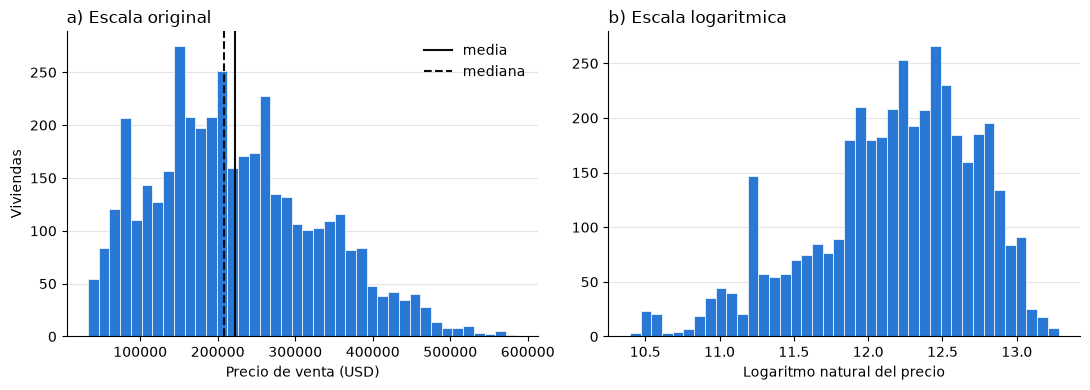

In [82]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
color = "#2a78d6"

axes[0].hist(df_reg["SalePrice"], bins=40, color=color, edgecolor="white", linewidth=0.5)
axes[0].axvline(df_reg["SalePrice"].mean(), color="#0b0b0b", linewidth=1.5, label="media")
axes[0].axvline(df_reg["SalePrice"].median(), color="#0b0b0b", linewidth=1.5, linestyle="--", label="mediana")
axes[0].set_title("a) Escala original", loc="left")
axes[0].set_xlabel("Precio de venta (USD)")
axes[0].set_ylabel("Viviendas")
axes[0].legend(frameon=False)

axes[1].hist(np.log(df_reg["SalePrice"]), bins=40, color=color, edgecolor="white", linewidth=0.5)
axes[1].set_title("b) Escala logaritmica", loc="left")
axes[1].set_xlabel("Logaritmo natural del precio")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()